# Planner scenarios

The test scenarios (`planner/tests/scenarios/*.json`), planned exactly as the boat does (`make_plan` in `service/planner.py`:
ShiftEnergy with `arrive_by`, SlowDown without), and plotted. `test_planner.py` runs the same scenarios and checks them:

    .venv/bin/pytest planner/tests -v

Add a scenario = add a JSON file to the folder; both the tests and this notebook pick it up.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scenarios as sc       # planner/tests/scenarios/ (the JSON files + run())

SKIP = ["very_long"]         # the planner has no time limit yet: this one doesn't finish (its test fails on purpose)
NAMES = [n for n in sc.SCENARIOS if n not in SKIP]

rows = []
for name in NAMES:
    s = sc.SCENARIOS[name]
    p, _ = sc.run(name)
    rows.append({"scenario": name, "expect": s["expect"], "planner": p["planner"], "feasible": p["summary"]["feasible"],
                 "start V": s["start_v"], "reserve": s["mission"]["reserve_v"], "lowest V": p["summary"]["min_v"],
                 "end V": p["summary"]["end_v"], "arrive by": s["mission"].get("arrive_by"), "arrival": p["summary"]["arrival"],
                 "hours planned": len(p["hourly"])})
table = pd.DataFrame(rows).set_index("scenario")
table["as expected"] = table.feasible == (table.expect == "feasible")
table

,expect,planner,feasible,start V,reserve,lowest V,end V,arrive by,arrival,hours planned,as expected
scenario,,,,,,,,,,,
deadline,feasible,shift-energy (0.4–1.0),True,24.35,23.0,24.350,24.730,2025-07-22T12:00:00Z,2025-07-21T19:55:00Z,174,True
low_start,feasible,shift-energy (0.4–1.0),True,23.30,23.0,23.300,24.628,2025-07-22T12:00:00Z,2025-07-21T10:15:00Z,174,True
no_deadline,feasible,"slow-down (1.0, min 0.4)",True,24.35,23.0,23.002,23.551,NaN,2025-07-19T18:57:00Z,109,True
start_below_reserve,feasible,shift-energy (0.4–1.0),False,22.80,23.0,22.800,24.628,2025-07-22T12:00:00Z,2025-07-21T10:15:00Z,174,False
too_fast,infeasible,"slow-down (1.0, min 0.4)",False,24.35,23.0,23.002,23.551,2025-07-16T12:00:00Z,2025-07-19T18:57:00Z,109,True


## Each scenario

Top: the hourly speed plan. Bottom: predicted battery voltage, reserve (red), deadline (dashed).

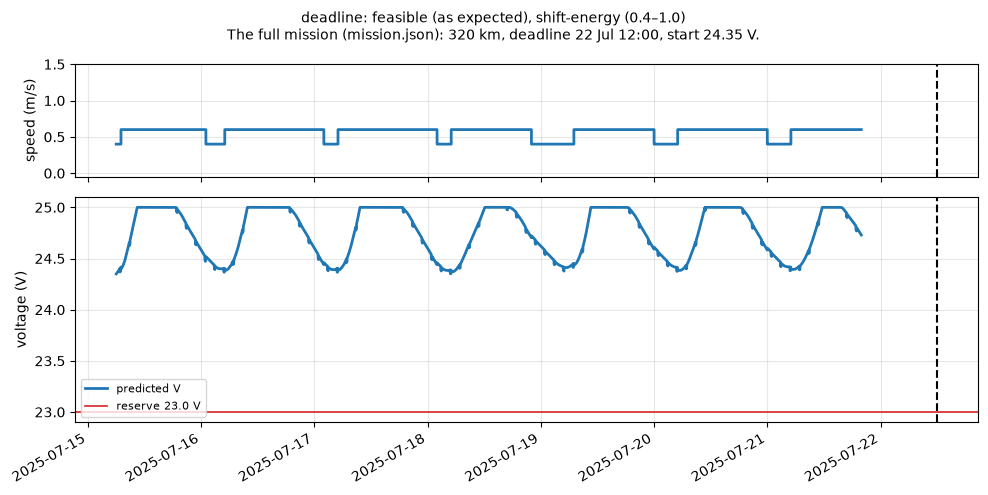

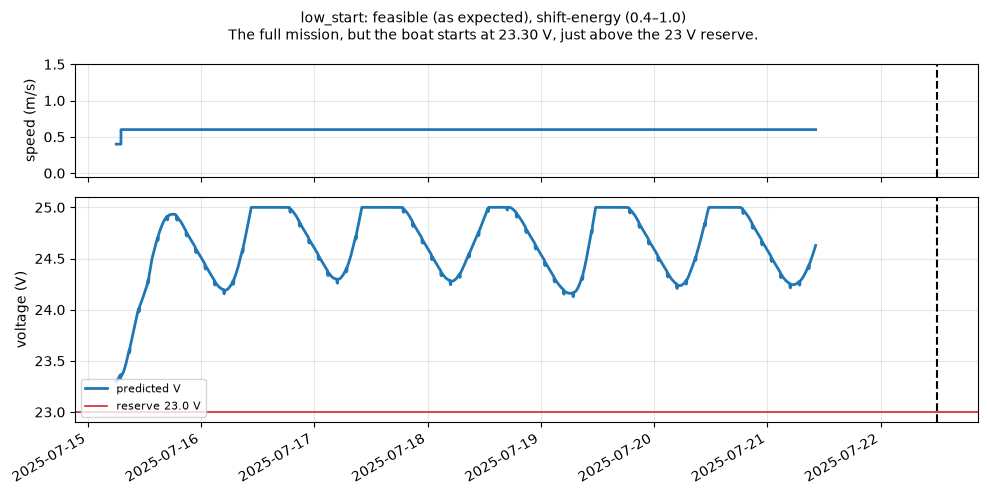

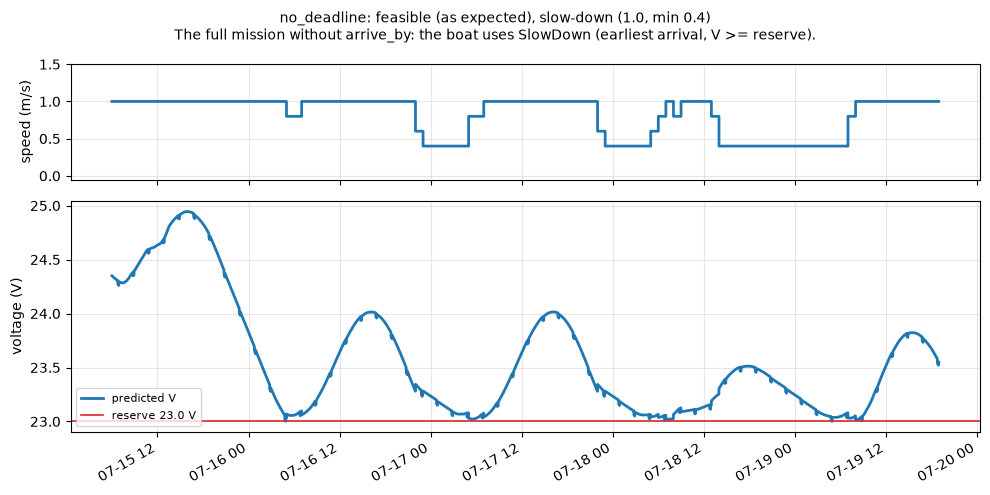

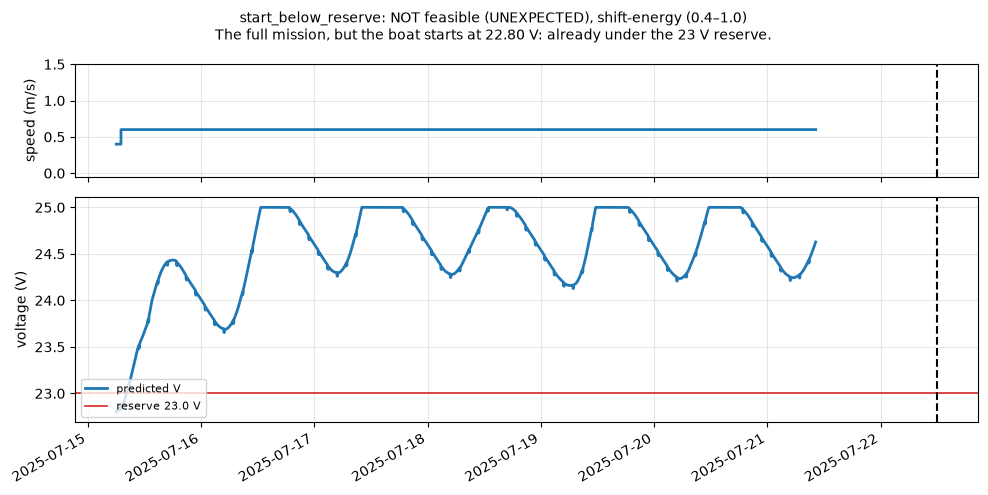

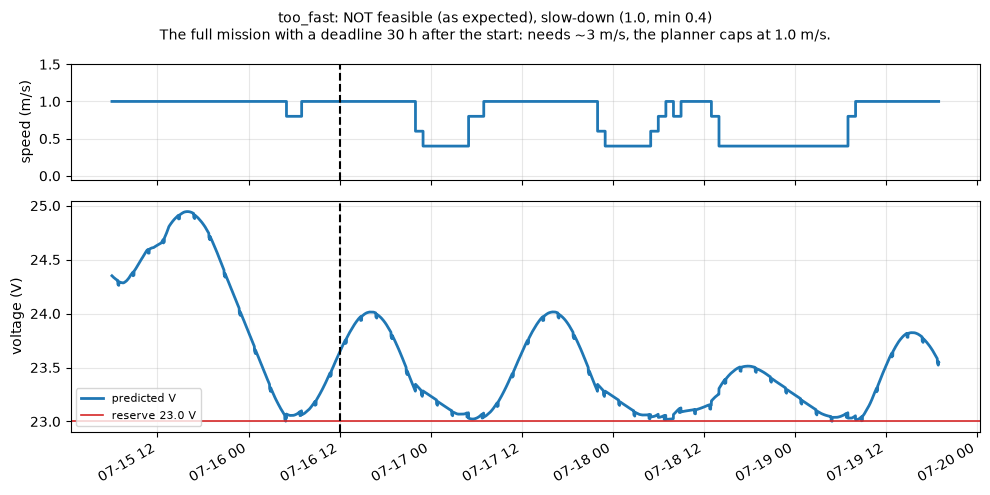

In [2]:
def show(name):
    s = sc.SCENARIOS[name]
    p, pred = sc.run(name)          # plan (decision) and prediction (per minute)
    ser = pred["series"]
    t = pd.to_datetime(ser["t"], unit="s", utc=True)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
    ax1.step(t, ser["speed"], where="post", color="C0", lw=2)
    ax1.set_ylabel("speed (m/s)"); ax1.set_ylim(-0.05, 1.5)
    ax2.plot(t, ser["v_batt"], color="C0", lw=2, label="predicted V")
    ax2.axhline(s["mission"]["reserve_v"], color="C3", lw=1.2, label=f"reserve {s['mission']['reserve_v']} V")
    if s["mission"].get("arrive_by"):
        for ax in (ax1, ax2):
            ax.axvline(pd.Timestamp(s["mission"]["arrive_by"]), color="k", ls="--", lw=1.5)
    ax2.set_ylabel("voltage (V)"); ax2.legend(fontsize=8, loc="lower left")
    sm = p["summary"]
    verdict = "feasible" if sm["feasible"] else "NOT feasible"
    ok = "as expected" if sm["feasible"] == (s["expect"] == "feasible") else "UNEXPECTED"
    fig.suptitle(f"{name}: {verdict} ({ok}), {p['planner']}\n{s['description']}", fontsize=10)
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    fig.autofmt_xdate(); plt.tight_layout(); plt.show()

for name in NAMES:
    show(name)